# TODO
- It would be really nice to have sampling frequencies.

In [1]:
import sys
import pathlib
import xarray as xr

sys.path.append("../src")

from ome_tiff_processing.image.image import OmeTiffFile
from ome_tiff_processing.image.selection import ROISelectionTool

In [2]:
leica_pyramidal_image = "../data/Leica1_36832_38432_1_3_1.ome.tiff"
tif = OmeTiffFile(leica_pyramidal_image)

reference_image = tif.sel(image=1, level=4, output_shape=list("XYS"))

In [3]:
roi_tool = ROISelectionTool(tif[1])

roi_tool.serve(reference_level=4,)

ROI selector running at http://127.0.0.1:8050


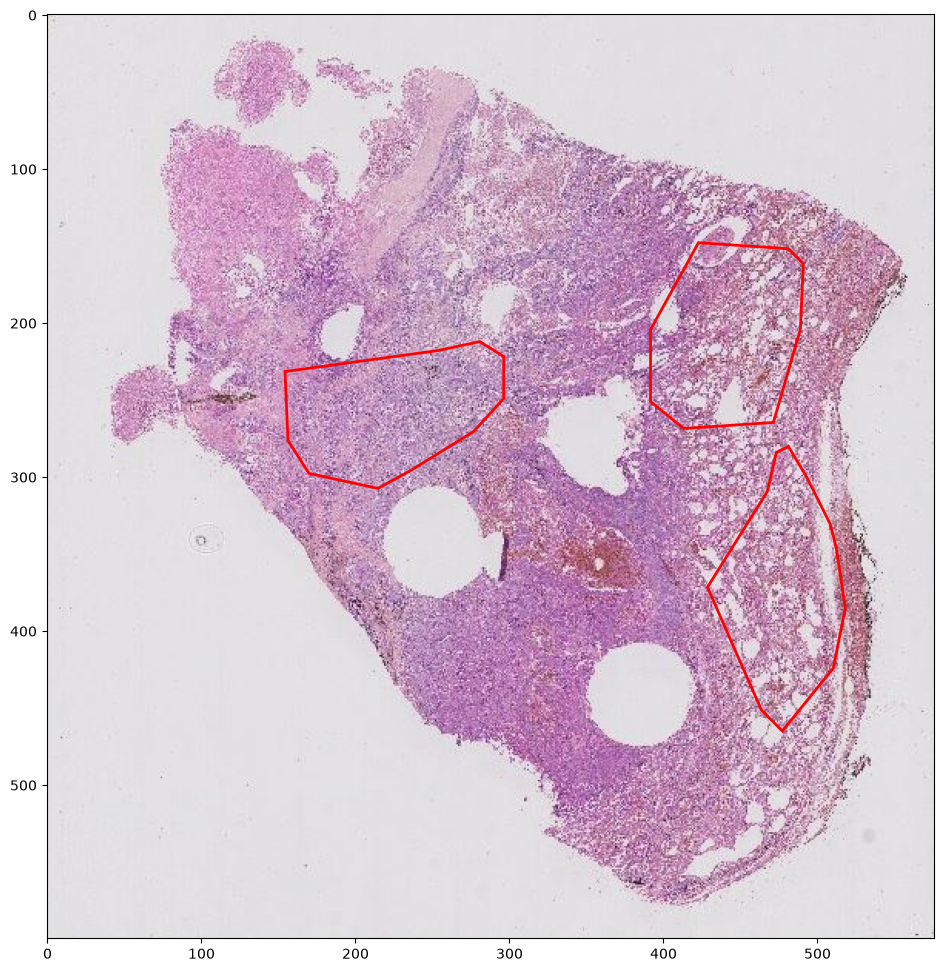

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

image = tif[1].sel(
    level=3,
    output_shape=("Y", "X", "S")
)

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(image)

polygons = roi_tool.get_polygons(target_level=3)

for p in range(len(polygons)):
    ax.add_patch(Polygon(
        polygons[f"roi_{p}"].as_numpy(),
        closed=True,
        fill=False,
        edgecolor="red",
        linewidth=2
    ))

plt.show()

In [12]:
for i in range(4):
    polygons = roi_tool.get_polygons(target_level=i)

In [14]:
polygons = roi_tool.get_polygons(target_level=0)
polygons.to_netcdf("../data/leica_image_1_level_0_roi.ncdf")

In [15]:
polygons = xr.load_dataset("../data/leica_image_1_level_0_roi.ncdf")
polygons

<xarray.Dataset> Size: 480B
Dimensions:     (vertex_2: 11, coordinate: 2, vertex_0: 10, vertex_1: 8)
Coordinates:
  * coordinate  (coordinate) object 16B 'X' 'Y'
Dimensions without coordinates: vertex_2, vertex_0, vertex_1
Data variables:
    roi_2       (vertex_2, coordinate) float64 176B 2.745e+04 ... 1.984e+04
    roi_0       (vertex_0, coordinate) float64 160B 9.879e+03 ... 1.397e+04
    roi_1       (vertex_1, coordinate) float64 128B 2.708e+04 ... 9.73e+03